# Exercise: Fourier transforms with `numpy.fft`

## Introduction

`numpy.fft` computes the Discrete Fourier Transform (DFT) - aka the spectrum -of a signal with the Fast Fourier Transform (FFT) algorithm.
It decomposes a signal into a sum of sinusoids, and gives the amplitude and phase of each frequency.

The steps are:

1. Compute the spectrum of a noisy 1D signal and find its frequencies (`fft`, `fftfreq`, `fftshift`)
2. Filter the signal in the Fourier space and go back to the direct space (`ifft`)
3. Remove a periodic pattern from an image with a 2D FFT (`fft2`, `ifft2`)

Useful documentation: https://numpy.org/doc/stable/reference/routines.fft.html

## Part I: spectrum of a 1D signal

In [1]:
import numpy as np

In [2]:
%matplotlib widget
# This requires ipympl
# Or for non-interactive plots: %matplotlib inline

from matplotlib import pyplot as plt

### The data

The following cell simulates a signal sampled at 1000 Hz during 1 second: the `clean` signal is the sum of two sinusoids and the measured `signal` has some added noise.

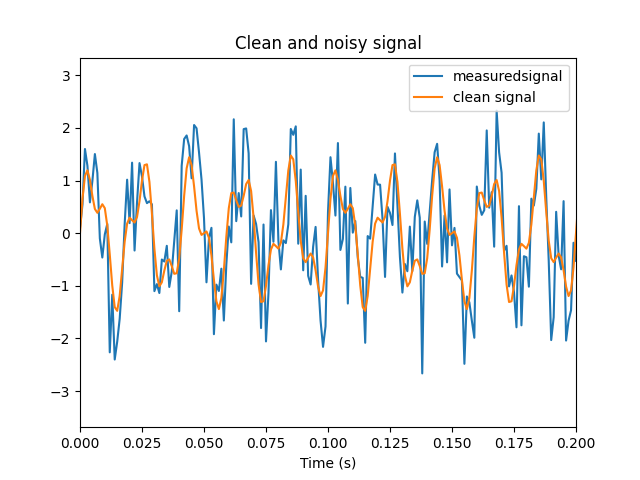

In [3]:
sampling_rate = 1000  # in Hz
t = np.arange(1000) / sampling_rate  # in s

rng = np.random.default_rng(seed=0)
clean = np.sin(2 * np.pi * 50 * t) + 0.5 * np.sin(2 * np.pi * 120 * t)
signal = clean  + rng.normal(scale=0.8, size=t.size)

fig = plt.figure()
plt.plot(t, signal, label="measuredsignal")
plt.plot(t, clean, label="clean signal")
plt.xlabel("Time (s)")
plt.xlim(0, 0.2)
plt.title("Clean and noisy signal")
plt.legend()

Note: the frequencies are hard to see in the noisy signal.

### Fourier transform

Compute the Fourier transform of `signal` (hint: `np.fft.fft`). What are its shape and dtype?

Compute the frequency associated with each element of the result (hint: `np.fft.fftfreq`, the `d` argument is the sampling period).

spectrum: (1000,) complex128
frequencies: [0. 1. 2. 3. 4.] ... [-5. -4. -3. -2. -1.]


Text(0.5, 1.0, 'Spectrum in numpy order')

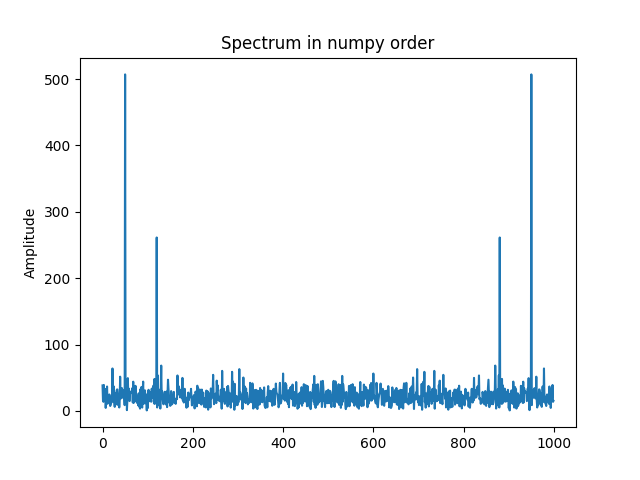

In [4]:
spectrum = np.fft.fft(signal)
frequencies = np.fft.fftfreq(len(signal),1/sampling_rate)
print("spectrum:", spectrum.shape, spectrum.dtype)
print("frequencies:", frequencies[:5], "...", frequencies[-5:])


fig = plt.figure()
#plt.plot(frequencies, np.abs(spectrum))
plt.plot(np.abs(spectrum))
#plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Spectrum in numpy order")

`np.fft.fft` and `np.fft.freqs` return the positive frequencies first, then the negative ones.
To reorder frequencies in ascending order, use `np.fft.fftshift` on both  `frequencies` AND `spectrum` to put the zero frequency at the center.

Text(0.5, 1.0, 'Spectrum with zero frequency at the center')

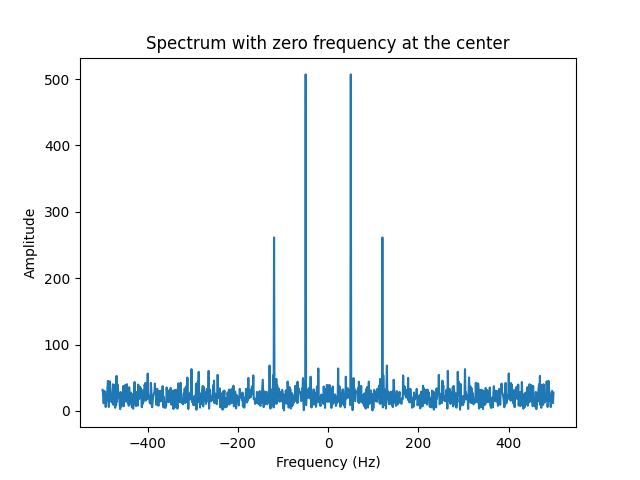

In [5]:
shifted_frequencies = np.fft.fftshift(frequencies)
shifted_spectrum = np.fft.fftshift(spectrum)

fig = plt.figure()
plt.plot(shifted_frequencies, np.abs(shifted_spectrum))
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Spectrum with zero frequency at the center")

For a real signal, the spectrum is symmetric: the amplitude at $-f$ is the same as at $f$.

Find the frequencies of the 2 highest peaks among the positive frequencies (hint: `np.argsort`) and comparer with the sines contained in the `clean` signal.

In [6]:
positive = np.abs(shifted_spectrum[shifted_frequencies>0])
peaks = shifted_frequencies[shifted_frequencies>0][np.argsort(positive)][-2:]
print("peaks at:", peaks, "Hz")

peaks at: [120.  50.] Hz


Note: as the negative frequencies of a real signal are redundant, `np.fft.rfft` and `np.fft.rfftfreq` compute only the positive ones.

### Back to direct space

Check that the inverse transform (hint: `np.fft.ifft`) of `spectrum` gives back `signal`.
What is the dtype of the result?

complex128 True


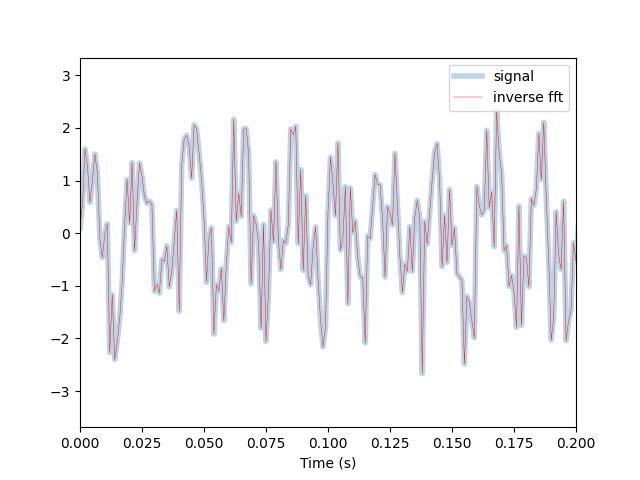

In [7]:
back = np.fft.ifft(spectrum)
print(back.dtype, np.allclose(back, signal))

fig = plt.figure()
plt.plot(t, signal, alpha=0.3, lw=4,label="signal")
plt.plot(t, back.real, 'r', lw=0.3,label="inverse fft")
plt.xlabel("Time (s)")
plt.xlim(0, 0.2)
plt.legend()

## Part II: filtering

### Denoising

We now want to clean signal and remove the background noise. This corresponds to all frequencies in the spectrum that have a spectrum value  below some threshhold to be determined (quite easy here).

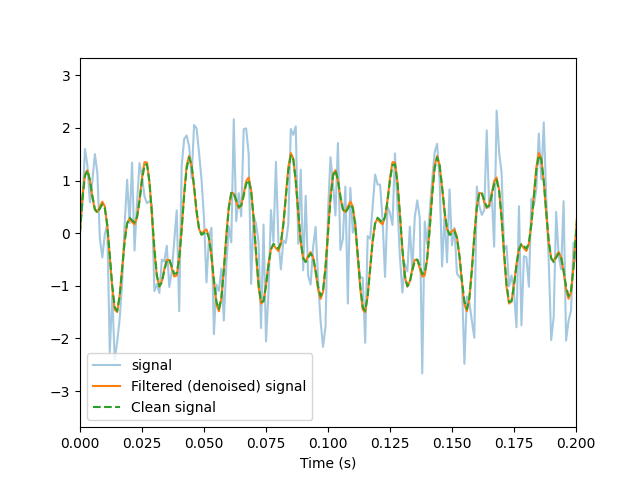

In [8]:
filtered_spectrum = spectrum.copy()
filtered_spectrum[np.abs(spectrum)<100] = 0.
filtered = np.fft.ifft(filtered_spectrum)

fig = plt.figure()
plt.plot(t, signal, alpha=0.4, label="signal")
plt.plot(t, filtered.real, label="Filtered (denoised) signal")
plt.plot(t, clean, "--", label="Clean signal")
plt.xlabel("Time (s)")
plt.xlim(0, 0.2)
plt.legend()

## Part III: 2D FFT

The following cell builds an image (a disk and a square) spoiled by a periodic stripe pattern, like the interference patterns sometimes seen on detectors.

Text(0.5, 1.0, 'Image with stripes')

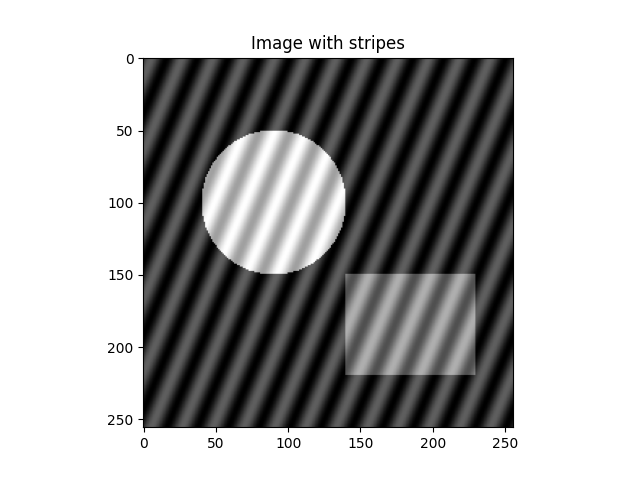

In [9]:
y, x = np.mgrid[0:256, 0:256]
objects = 1.0 * ((x - 90) ** 2 + (y - 100) ** 2 < 50 ** 2)
objects[150:220, 140:230] = 0.5
stripes = 0.3 * np.sin(2 * np.pi * (12 * x + 5 * y) / 256)
image = objects + stripes

fig = plt.figure()
plt.imshow(image, cmap="gray")
plt.title("Image with stripes")

Compute the 2D Fourier transform of the image (hint: `np.fft.fft2`) and shift the zero frequency to the center of the array.

Text(0.5, 1.0, 'log(1 + |FFT|), zero frequency at the center')

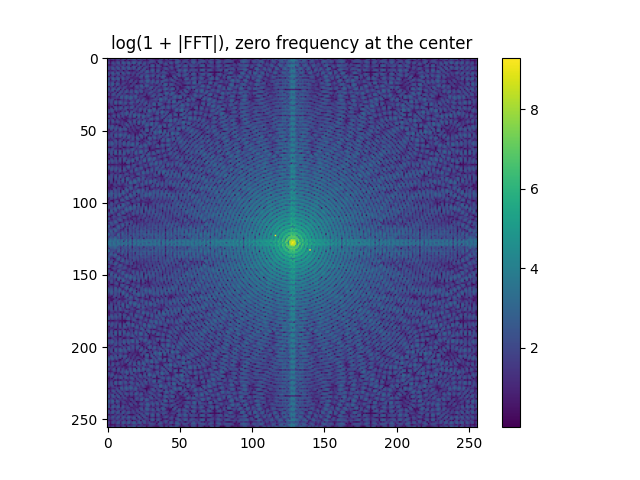

In [10]:
image_spectrum = np.fft.fftshift(np.fft.fft2(image))
fig = plt.figure()
plt.imshow(np.log(1 + np.abs(image_spectrum)), cmap="viridis")
plt.colorbar()
plt.title("log(1 + |FFT|), zero frequency at the center")

Apart from the center, two isolated bright points correspond to the stripes.

* Find their positions (hint: hover the plot, or `np.argmax` after setting the center to 0, and `np.unravel_index`)
* Set them to 0
* Undo the shift (hint: `np.fft.ifftshift`) and compute the inverse transform (hint: `np.fft.ifft2`), keeping the real part

Text(0.5, 1.0, 'Stripes removed')

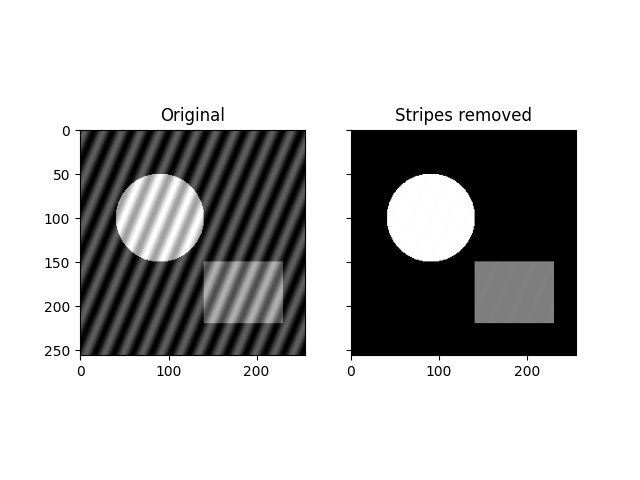

In [11]:
image_spectrum[123,116] = 0.
image_spectrum[133,140] = 0.
cleaned = np.abs(np.fft.ifft2(np.fft.ifftshift(image_spectrum)))
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True)
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(cleaned, cmap="gray")
axes[1].set_title("Stripes removed")

### Bonus: low-pass filter in 2D

Keep only the frequencies within a radius of 20 pixels around the center of `image_spectrum`, and go back to the direct space. What happens to the edges of the objects? Why?

Text(0.5, 1.0, 'Low-pass filtered')

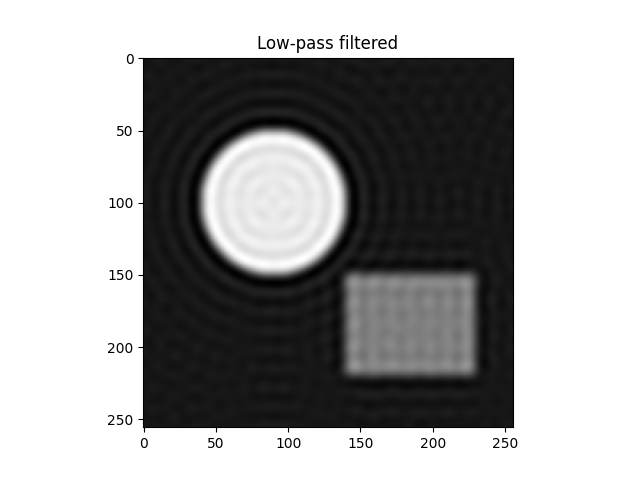

In [12]:
radius = np.sqrt((x - 128) ** 2 + (y - 128) ** 2)
lowpass_spectrum = np.where(radius <= 20, image_spectrum, 0) # Keep only low frequencies (i.e. frequencies that are contained in a disc centered at the origin of the Fourier space)
blurred = np.fft.ifft2(np.fft.ifftshift(lowpass_spectrum)).real

fig = plt.figure()
plt.imshow(blurred, cmap="gray")
plt.title("Low-pass filtered")


## Solution

<details><summary>...</summary>


```python
# Part I

import numpy as np

# Fourier transform
spectrum = np.fft.fft(signal)  # complex, same length as signal
frequencies = np.fft.fftfreq(signal.size, d=1 / sampling_rate)

shifted_frequencies = np.fft.fftshift(frequencies)
shifted_spectrum = np.fft.fftshift(spectrum)

positive = frequencies > 0
peaks = frequencies[positive][np.argsort(np.abs(spectrum[positive]))[-2:]]

# Part II

# Back to the direct space
back = np.fft.ifft(spectrum)  # complex, with a ~0 imaginary part

# Low-pass filter
filtered_spectrum = spectrum.copy()
filtered_spectrum[np.abs(frequencies) > 80] = 0
filtered = np.fft.ifft(filtered_spectrum).real

# Band-pass filter
band_spectrum = np.where((np.abs(frequencies) >= 45) & (np.abs(frequencies) <= 55), spectrum, 0)
band = np.fft.ifft(band_spectrum).real

# Part III

image_spectrum = np.fft.fftshift(np.fft.fft2(image))

# Find the 2 peaks of the stripes
amplitude = np.abs(image_spectrum)
amplitude[128, 128] = 0  # Center (zero frequency)
for _ in range(2):
    row, col = np.unravel_index(np.argmax(amplitude), amplitude.shape)
    print("peak at:", row, col)  # (123, 116) and (133, 140)
    amplitude[row, col] = 0
    image_spectrum[row, col] = 0

cleaned = np.fft.ifft2(np.fft.ifftshift(image_spectrum)).real

# Bonus: low-pass filter in 2D
radius = np.sqrt((x - 128) ** 2 + (y - 128) ** 2)
lowpass_spectrum = np.where(radius <= 20, image_spectrum, 0)
blurred = np.fft.ifft2(np.fft.ifftshift(lowpass_spectrum)).real
# Sharp edges need high frequencies: without them, edges are blurred, with ripples around them
```

</details>